# Social Media Usage and Emotional Well-Being
**Exploratory Data Analysis and Statistical Testing | Python**

## Project overview
This notebook examines associations between social media activity and the **dominant emotion reported** by individuals in the *Social Media Usage and Emotional Well-Being* dataset. It uses descriptive statistics, visualizations, and a chi-square test of independence.

**Research focus:** Do engagement patterns, primary social media platform, daily usage time, and age vary across reported emotional categories?

> **Scope:** This is an exploratory, observational analysis—not a predictive model or a causal study. Differences in the dataset do not establish that social media use causes emotional outcomes.

### Dataset fields
- `User_ID`: user identifier
- `Age`: age in years
- `Gender`: reported gender
- `Platform`: primary social media platform
- `Daily_Usage_Time (minutes)`: daily usage duration
- `Posts_Per_Day`, `Likes_Received_Per_Day`, `Comments_Received_Per_Day`, `Messages_Sent_Per_Day`: engagement measures
- `Dominant_Emotion`: reported emotional category

**Data source:** Emirhan Bulut (2024), *Social Media Usage and Emotional Well-Being*, Kaggle. https://doi.org/10.34740/KAGGLE/DSV/8460631

### Reproducing this notebook
1. Install the packages listed in `requirements.txt`.
2. Obtain the dataset from the source above and place `train.csv` in the same directory as this notebook.
3. Run the notebook cells in order.

## 1. Import libraries and load data


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Download train.csv from the dataset source linked above.
data = pd.read_csv("train.csv")
data.head()


## 2. Data quality and preparation

First, inspect missing values before making changes to the dataset.


In [116]:
data.isna().sum()

User_ID                       0
Age                           0
Gender                        1
Platform                      1
Daily_Usage_Time (minutes)    1
Posts_Per_Day                 1
Likes_Received_Per_Day        1
Comments_Received_Per_Day     1
Messages_Sent_Per_Day         1
Dominant_Emotion              1
dtype: int64

The original data inspection identified an invalid record with `User_ID` equal to `Tabii`. The following step excludes that record and checks missing values again. This is a dataset-specific cleaning decision; it should not be generalized to other datasets.


In [ ]:
# Exclude the invalid dataset record identified during inspection.
social = data.loc[data["User_ID"] != "Tabii"].copy()

# Confirm remaining missing values.
social.isna().sum()


After cleaning, review the descriptive summary to understand the number of observations, category frequencies, and numeric ranges.


In [118]:
social.describe(include="all")

,User_ID,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
count,1000,1000,1000,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000
unique,1000,18,18,7,NaN,NaN,NaN,NaN,NaN,6
top,1000,27,Female,Instagram,NaN,NaN,NaN,NaN,NaN,Happiness
freq,1,92,344,250,NaN,NaN,NaN,NaN,NaN,200
mean,NaN,NaN,NaN,NaN,95.950000,3.321000,39.898000,15.611000,22.560000,NaN
std,NaN,NaN,NaN,NaN,38.850442,1.914582,26.393867,8.819493,8.516274,NaN
min,NaN,NaN,NaN,NaN,40.000000,1.000000,5.000000,2.000000,8.000000,NaN
25%,NaN,NaN,NaN,NaN,65.000000,2.000000,20.000000,8.000000,17.750000,NaN
50%,NaN,NaN,NaN,NaN,85.000000,3.000000,33.000000,14.000000,22.000000,NaN
75%,NaN,NaN,NaN,NaN,120.000000,4.000000,55.000000,22.000000,28.000000,NaN


## 3. Research questions and working hypotheses

The analysis explores four questions:

1. **Engagement:** Do posting, likes, comments, and messaging patterns differ across dominant emotions? The initial hypothesis is that higher engagement is associated with more negative reported emotions.
2. **Platform:** Does the distribution of dominant emotions differ by primary social media platform?
3. **Usage duration:** Is longer daily social media usage associated with more negative reported emotions?
4. **Age:** Are there meaningful descriptive differences in age across emotional categories?

The boxplots below provide exploratory comparisons. Only the **platform–emotion relationship** is evaluated using a formal hypothesis test in this notebook.

## 4. Engagement measures by dominant emotion

### Posts per day
The following boxplot compares the distributions of daily posting frequency across emotional categories.


<Figure size 1000x500 with 0 Axes>

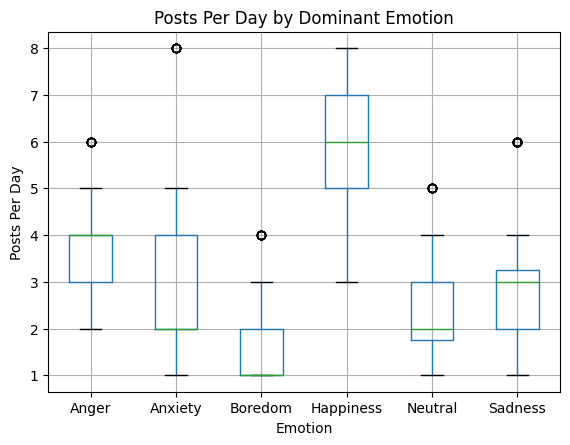

In [119]:
plt.figure(figsize = (10,5))
social.boxplot(column = "Posts_Per_Day", by = "Dominant_Emotion")

plt.title("Posts Per Day by Dominant Emotion")
plt.suptitle("")
plt.xlabel("Emotion")
plt.ylabel("Posts Per Day")
plt.show()

**Interpretation:** The happiness group appears to have a higher median number of posts per day than several other groups. Boxplots also reveal differences in spread and possible outliers. These descriptive patterns do not establish a causal effect or statistically test the engagement hypothesis.


### Likes received per day
Compare the median, spread, and outliers of daily likes received across reported emotions.


<Figure size 1000x500 with 0 Axes>

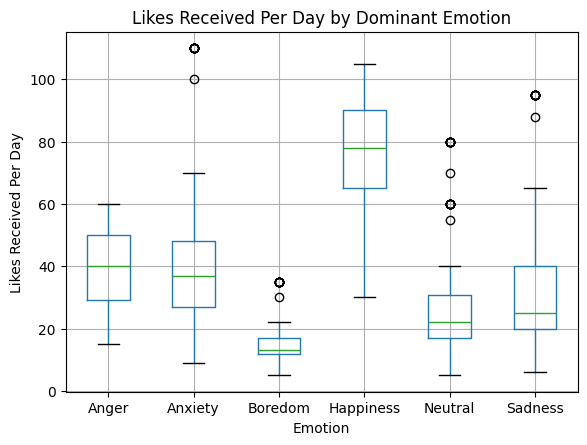

In [120]:
plt.figure(figsize = (10,5))
social.boxplot(column = "Likes_Received_Per_Day", by = "Dominant_Emotion")

plt.title("Likes Received Per Day by Dominant Emotion")
plt.suptitle("")
plt.xlabel("Emotion")
plt.ylabel("Likes Received Per Day")
plt.show()

**Interpretation:** The happiness group appears to have the highest median number of likes received, while boredom appears lower. This is an association within the sample, not evidence that receiving fewer likes causes boredom.


### Comments received per day
This boxplot compares daily comments received across emotional categories.


<Figure size 1000x500 with 0 Axes>

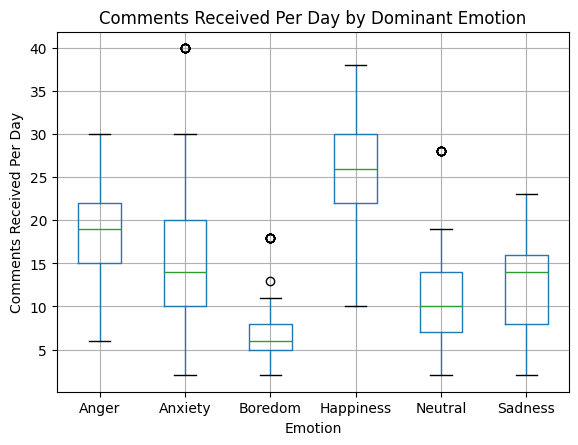

In [121]:
plt.figure(figsize = (10,5))
social.boxplot(column = "Comments_Received_Per_Day", by = "Dominant_Emotion")

plt.title("Comments Received Per Day by Dominant Emotion")
plt.suptitle("")
plt.xlabel("Emotion")
plt.ylabel("Comments Received Per Day")
plt.show()

**Interpretation:** The happiness group appears to have a relatively high median number of comments, while the anxiety group shows substantial variation. Differences in variability do not explain *why* those differences occur.


### Messages sent per day
This boxplot compares messaging activity across reported emotions.


<Figure size 1000x500 with 0 Axes>

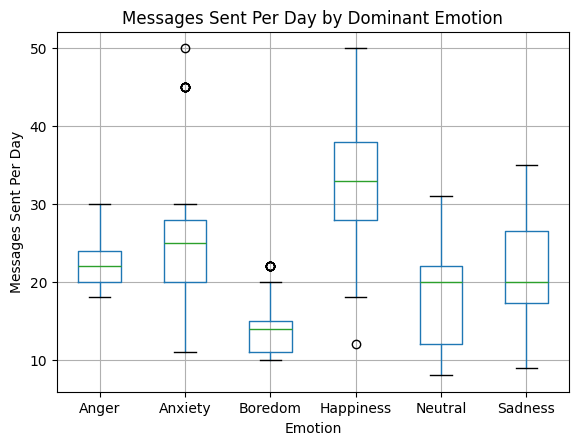

In [122]:
plt.figure(figsize = (10,5))
social.boxplot(column = "Messages_Sent_Per_Day", by = "Dominant_Emotion")

plt.title("Messages Sent Per Day by Dominant Emotion")
plt.suptitle("")
plt.xlabel("Emotion")
plt.ylabel("Messages Sent Per Day")
plt.show()

**Interpretation:** Happiness again appears associated with a relatively high median number of messages sent. The anxiety category shows a broad distribution. The chart does not establish that anxiety causes any particular messaging behavior.


## 5. Primary platform and dominant emotion

The stacked bar chart shows the **proportion of each emotion within each platform**. Because each platform's bar sums to 100%, the chart is useful for comparing emotion distributions even when platform sample sizes differ.


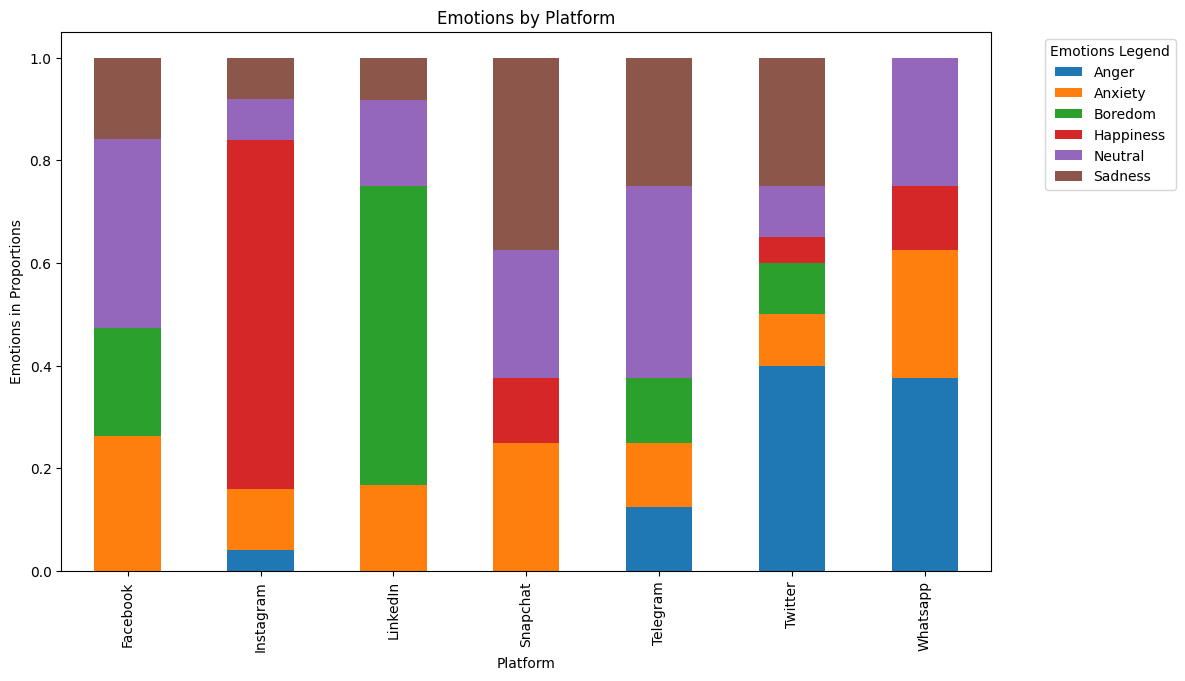

In [123]:
emotion = pd.crosstab(social["Platform"], social["Dominant_Emotion"], normalize = "index")

emotion.plot(kind = "bar", stacked = True, figsize = (12,7))
plt.title("Emotions by Platform")
plt.xlabel("Platform")
plt.ylabel("Emotions in Proportions")
plt.legend(bbox_to_anchor = (1.05,1), title = "Emotions Legend")
plt.show()

**Interpretation:** The chart suggests that emotional categories are distributed differently across platforms. For example, anger appears relatively common among Twitter and WhatsApp users in this sample, while happiness represents a large share of Instagram users. These observations motivate a formal association test; they do not imply that a platform causes a particular emotion.


### Chi-square test of independence

**Null hypothesis (H₀):** Primary platform and dominant emotion are independent.

**Alternative hypothesis (H₁):** Primary platform and dominant emotion are associated.

The contingency table below contains counts for each platform–emotion combination. A chi-square test then evaluates whether the observed counts differ from those expected under independence.


In [124]:
table = pd.crosstab(social["Platform"], social["Dominant_Emotion"])
print("Contingency Table:\n", table)

Contingency Table:
 Dominant_Emotion  Anger  Anxiety  Boredom  Happiness  Neutral  Sadness
Platform                                                              
Facebook              0       50       40          0       70       30
Instagram            10       30        0        170       20       20
LinkedIn              0       20       70          0       20       10
Snapchat              0       20        0         10       20       30
Telegram             10       10       10          0       30       20
Twitter              80       20       20         10       20       50
Whatsapp             30       20        0         10       20        0


In [125]:
chi2 = stats.chi2_contingency(table)

chiStat = chi2[0]
print("\nChi-Square Statistic:", chiStat)
pValue = chi2[1]
print("\nP-Value:", pValue)


Chi-Square Statistic: 1003.9059462853966

P-Value: 7.686476515335924e-192


**Test result:** The recorded chi-square statistic is approximately **1003.91**, with a p-value of approximately **7.69 × 10⁻¹⁹²**. Since the p-value is below 0.05, the test rejects the null hypothesis of independence in this dataset.

**Interpretation:** There is strong statistical evidence of an association between primary platform and reported dominant emotion. This does **not** establish causation, and the magnitude of the chi-square statistic alone should not be treated as an effect size. The usual chi-square assumptions, including adequate expected cell counts, should be checked when interpreting the result.


## 6. Daily usage time by dominant emotion

This boxplot explores whether the distribution of daily social media usage time varies across reported emotional categories.


<Figure size 1000x500 with 0 Axes>

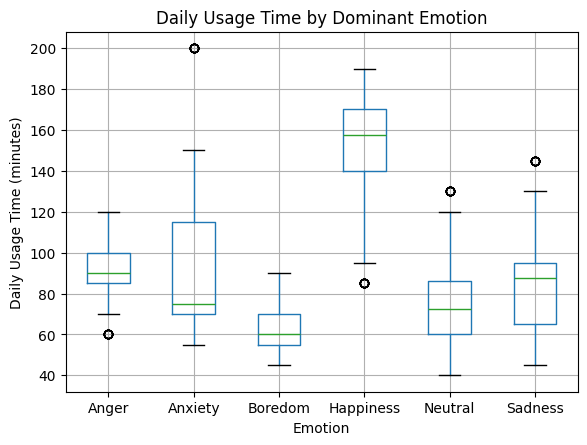

In [126]:
plt.figure(figsize = (10,5))
social.boxplot(column = "Daily_Usage_Time (minutes)", by = "Dominant_Emotion")

plt.title("Daily Usage Time by Dominant Emotion")
plt.suptitle("")
plt.xlabel("Emotion")
plt.ylabel("Daily Usage Time (minutes)")
plt.show()

**Interpretation:** The happiness category appears to have a relatively high median daily usage time, while boredom shows a narrower range. These observations do not demonstrate that social media use prevents boredom or improves emotional well-being. No formal test of usage-time differences is performed here.


## 7. Age and dominant emotion

Calculate the average age within each emotional category and visualize the group means. This is a descriptive comparison rather than a test of statistical significance.


In [ ]:
# Convert age values to numeric before calculating group means.
social["Age"] = pd.to_numeric(social["Age"], errors="coerce")
meanAge = social.groupby("Dominant_Emotion")["Age"].mean()
print(meanAge)


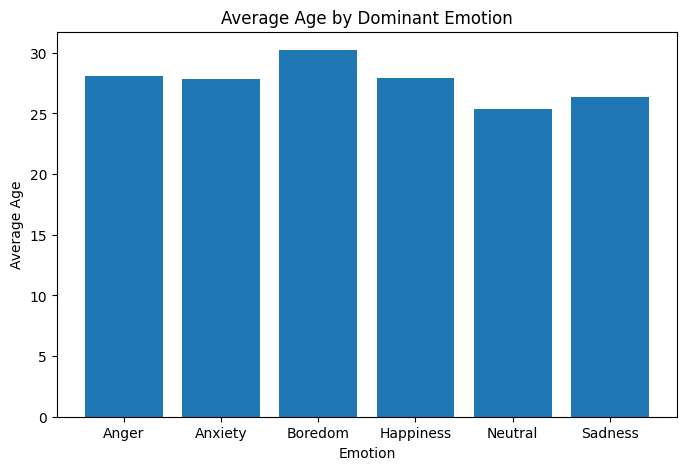

In [128]:
emotions = meanAge.index.tolist()
ages = meanAge.values.tolist()

plt.figure(figsize = (8,5))
plt.bar(emotions, ages)
plt.title("Average Age by Dominant Emotion")
plt.xlabel("Emotion")
plt.ylabel("Average Age")
plt.show()

**Interpretation:** The group means are relatively close, generally falling within the mid-to-late twenties or around age 30. The next step compares those means with the overall sample mean and standard deviation.


In [129]:
totalMean = social["Age"].mean()
totalStdDev = social["Age"].std()

print("Overall mean:", totalMean)
print("Overall standard deviation:", totalStdDev)

diff = meanAge - totalMean
print("\nDifference of overall mean and group means:\n", diff)

Overall mean: 27.5
Overall standard deviation: 3.9414732356830275

Difference of overall mean and group means:
 Dominant_Emotion
Anger        0.614754
Anxiety      0.320513
Boredom      2.730769
Happiness    0.424731
Neutral     -2.119565
Sadness     -1.157534
Name: Age, dtype: float64


The recorded overall mean age is **27.5 years**, with a standard deviation of approximately **3.94 years**. Group means differ from the overall mean by roughly **−2.12 to +2.73 years**.

These differences are modest relative to the sample's overall age spread. However, comparing mean differences with one standard deviation is **not a formal significance test**; the analysis therefore cannot conclude whether age differences are statistically significant.


## 8. Conclusion

This exploratory analysis examined social media engagement, platform choice, daily usage duration, and age in relation to reported dominant emotion.

- **Engagement:** The boxplots do not consistently support the initial expectation that higher engagement corresponds to more negative reported emotions. These are descriptive comparisons, so the hypothesis has not been formally disproved.
- **Platform:** The emotion distribution differs visibly across platforms. A chi-square test found strong evidence of an association between primary platform and dominant emotion in the analyzed dataset.
- **Usage duration:** The daily-usage boxplot did not show a simple pattern in which longer usage consistently aligned with more negative reported emotions.
- **Age:** Mean ages vary somewhat by emotion, but this notebook does not conduct a formal significance test for age differences.

### Limitations and next steps

The findings are **associational, not causal**. The notebook does not train a predictive model, and the results should not be interpreted as demonstrating that a platform or engagement behavior causes a particular emotional state. The dataset's sampling and measurement characteristics also affect generalizability.

Possible extensions include checking expected counts for the chi-square test, calculating an association effect size such as Cramér's V, performing suitable statistical comparisons for numeric variables, and—if prediction is the goal—training and evaluating a classifier using a separate test set.

## References

- Bulut, E. (2024). *Social Media Usage and Emotional Well-Being* [Dataset]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/8460631
- Plotly. *Bar charts*. https://plotly.com/python/bar-charts/
- GeeksforGeeks. *Python Pearson's chi-square test*. https://www.geeksforgeeks.org/python/python-pearsons-chi-square-test/
